# Hong Kong Mortality and Term-Life Pricing — Analysis

This notebook **imports the project's own modules** (`hk_mortality.pricing`, `hk_mortality.analysis`, `hk_mortality.plots`) and reproduces the pricing and comparison results that are also saved under `results/`. It contains **no duplicated pricing logic** — every number comes from the same code that the `scripts/` and `tests/` use.

Run from the project root, top to bottom.

In [1]:
import sys
from pathlib import Path

import pandas as pd

# Locate the project root (the directory that contains src/hk_mortality)
# regardless of the kernel's working directory, then make the package
# importable.  This mirrors the sys.path setup in scripts/ and tests/.
def _project_root() -> Path:
    for candidate in [Path.cwd(), *Path.cwd().parents]:
        if (candidate / 'src' / 'hk_mortality').exists():
            return candidate
    raise RuntimeError('Could not locate project root (src/hk_mortality not found)')

ROOT = _project_root()
sys.path.insert(0, str(ROOT / 'src'))

from hk_mortality import analysis, config, plots
from hk_mortality.pricing import BASE_INPUTS, load_tidy, price_case

print(f'project root: {ROOT}')
print(
    f'inputs: issue_age={BASE_INPUTS.issue_age}, term={BASE_INPUTS.term}, '
    f'benefit={BASE_INPUTS.benefit:,.0f}, '
    f'interest_rate={BASE_INPUTS.interest_rate:.0%}'
)

project root: /Users/kingstonpoon/Desktop/Mortality_pricing
inputs: issue_age=40, term=20, benefit=1,000,000, interest_rate=3%


In [2]:
tidy = load_tidy()

cases = sorted(
    set(map(tuple, tidy[['reference_year', 'sex']].drop_duplicates().values.tolist()))
)
print(f'rows: {len(tidy)}')
print(f'cases (reference_year, sex): {cases}')
print(f'age range: {tidy["age"].min()}..{tidy["age"].max()}')

tidy.head()

rows: 400
cases (reference_year, sex): [(2016, 'female'), (2016, 'male'), (2021, 'female'), (2021, 'male')]
age range: 0..99


,reference_year,sex,age,qx,lx
0,2016,female,0,0.001719,1000000
1,2016,female,1,0.000226,998281
2,2016,female,2,0.000180,998055
3,2016,female,3,0.000141,997875
4,2016,female,4,0.000108,997735


## Pricing method (plain language)

For a policy issued at exact age 40 with a 20-year term and a HKD 1,000,000 benefit paid at the **end** of the policy year of death:

1. The life starts each policy year with a survival probability `survival_to_start` (equal to 1 at the start of year 1).
2. The probability of dying in policy year *k* is `survival_to_start × qx[attained age]`.
3. The expected claim in that year is the benefit times that death probability.
4. It is discounted from the end of year *k* back to inception using `(1 + 3%)^(−k)`.
5. Survival is then updated by multiplying by `(1 − qx)`.

The **net single premium** is the sum of those discounted expected claims. This is an actuarial illustration, **not** a commercial quote.

In [3]:
rows = []
for reference_year, sex in config.MORTALITY_CASES:
    premium, audit = price_case(tidy, reference_year, sex, BASE_INPUTS)
    rows.append(
        {'reference_year': reference_year, 'sex': sex,
         'net_single_premium': premium}
    )

comparison = pd.DataFrame(rows)
comparison['net_single_premium'] = comparison['net_single_premium'].round(2)
comparison

,reference_year,sex,net_single_premium
0,2016,male,38503.39
1,2016,female,20651.09
2,2021,male,36947.43
3,2021,female,19725.23


### How one policy-year row contributes

Take the first policy year of the 2021 male case. The audit table below is the year-by-year cash-flow used to price the contract. Each row's `pv_claim` is discounted back to inception; their sum equals the premium exactly.

In [4]:
premium, audit = price_case(tidy, 2021, 'male', BASE_INPUTS)

print(f'net single premium (2021 male) = HKD {premium:,.2f}')
print(f'sum of pv_claim column          = HKD {audit["pv_claim"].sum():,.2f}')
print()

r = audit.iloc[0]
print('Policy year 1 (attained age 40) breakdown:')
print(f'  survival_to_start = {r["survival_to_start"]}')
print(f'  qx                = {r["qx"]}')
print(f'  death_probability = survival_to_start * qx = {r["death_probability"]}')
print(f'  discount_factor   = (1.03)^-1 = {r["discount_factor"]:.6f}')
print(f'  expected_claim    = benefit * death_probability = {r["expected_claim"]:,.2f}')
print(f'  pv_claim          = expected_claim * discount_factor = {r["pv_claim"]:,.2f}')

audit[['policy_year', 'attained_age', 'qx', 'survival_to_start',
       'death_probability', 'discount_factor', 'expected_claim', 'pv_claim']].head()

net single premium (2021 male) = HKD 36,947.43
sum of pv_claim column          = HKD 36,947.43

Policy year 1 (attained age 40) breakdown:
  survival_to_start = 1.0
  qx                = 0.00091104
  death_probability = survival_to_start * qx = 0.00091104
  discount_factor   = (1.03)^-1 = 0.970874
  expected_claim    = benefit * death_probability = 911.04
  pv_claim          = expected_claim * discount_factor = 884.50


,policy_year,attained_age,qx,survival_to_start,death_probability,discount_factor,expected_claim,pv_claim
0,1,40,0.000911,1.000000,0.000911,0.970874,911.040000,884.504854
1,2,41,0.001014,0.999089,0.001013,0.942596,1012.736515,954.601296
2,3,42,0.001136,0.998076,0.001134,0.915142,1133.764686,1037.555296
3,4,43,0.001279,0.996942,0.001275,0.888487,1274.610872,1132.475251
4,5,44,0.001440,0.995668,0.001434,0.862609,1434.199795,1237.153342


## Analysis 1 — 2016 vs 2021 mortality basis

For each sex, everything is held constant except the reference-year mortality schedule. The difference is entirely attributable to the change in the mortality basis.

In [5]:
comp = []
for sex in ('male', 'female'):
    c = analysis.compare_years(tidy, sex, BASE_INPUTS)
    comp.append(
        {'sex': sex,
         'premium_2016': c.premium_2016,
         'premium_2021': c.premium_2021,
         'absolute_diff_2021_minus_2016': c.absolute_diff,
         'pct_diff_2021_vs_2016': c.pct_diff}
    )

pd.DataFrame(comp).round(4)

,sex,premium_2016,premium_2021,absolute_diff_2021_minus_2016,pct_diff_2021_vs_2016
0,male,38503.3863,36947.4261,-1555.9601,-4.0411
1,female,20651.0852,19725.2257,-925.8595,-4.4833


## Analysis 2 — interest-rate sensitivity

The 2021 basis priced at constant annual effective discount rates of 2%, 3% and 4%.

In [6]:
sens = analysis.interest_sensitivity(tidy, BASE_INPUTS, rates=(0.02, 0.03, 0.04))
sens[sens['reference_year'] == 2021][['reference_year', 'sex', 'interest_rate', 'net_single_premium']].round(2)

,reference_year,sex,interest_rate,net_single_premium
6,2021,male,0.02,41786.12
7,2021,male,0.03,36947.43
8,2021,male,0.04,32799.68
9,2021,female,0.02,22300.10
10,2021,female,0.03,19725.23
11,2021,female,0.04,17516.48


## Analysis 3 — 10% mortality stress

Every covered `qx` is multiplied by 1.10 (capped at 1) and survival is recomputed from the stressed `qx`. This is an **arbitrary what-if assumption**, not a forecast, confidence interval, or regulatory calibration.

In [7]:
stress_rows = []
for reference_year, sex in config.MORTALITY_CASES:
    s = analysis.stress_premium(tidy, reference_year, sex, BASE_INPUTS)
    stress_rows.append(
        {'reference_year': reference_year, 'sex': sex,
         'premium_base': s.premium_base,
         'premium_stressed': s.premium_stressed,
         'absolute_diff': s.absolute_diff,
         'pct_diff': s.pct_diff}
    )

pd.DataFrame(stress_rows).round(2)

,reference_year,sex,premium_base,premium_stressed,absolute_diff,pct_diff
0,2016,male,38503.39,42250.19,3746.80,9.73
1,2016,female,20651.09,22686.86,2035.77,9.86
2,2021,male,36947.43,40546.97,3599.54,9.74
3,2021,female,19725.23,21670.83,1945.60,9.86


## Charts

The charts are written to `results/` together with the CSV that underlies each one.

/Users/kingstonpoon/Desktop/Mortality_pricing/results/mortality_curves.png


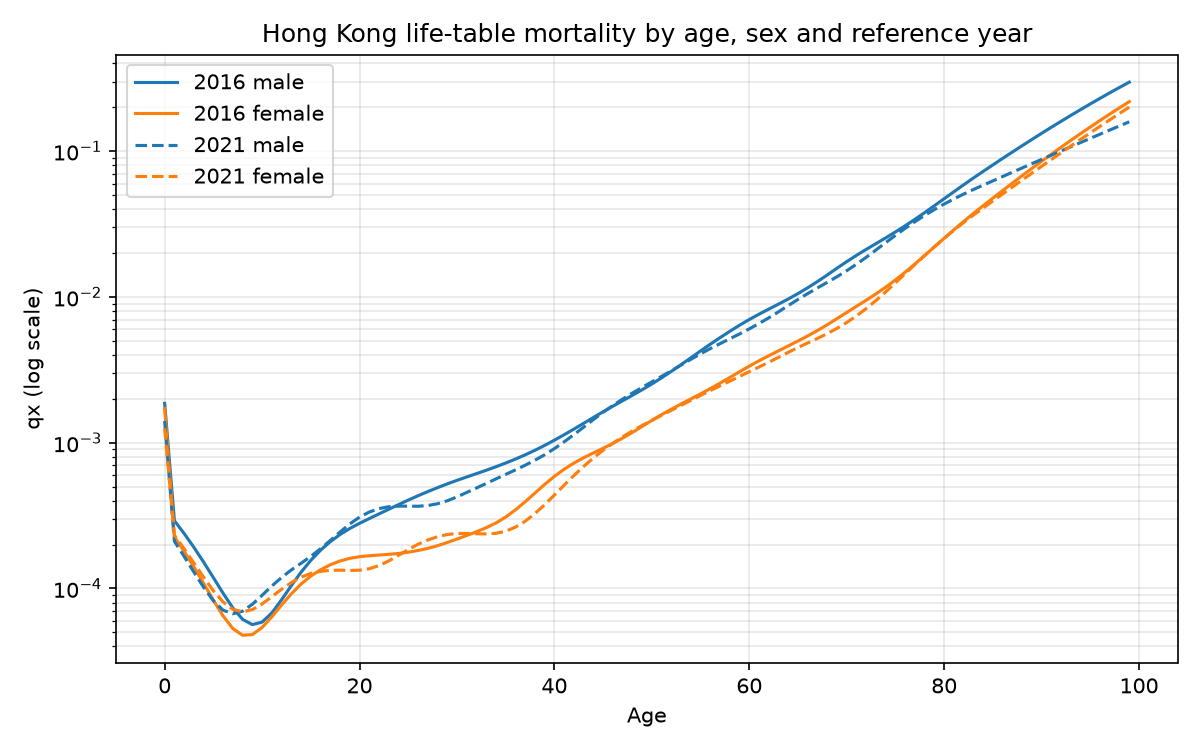

/Users/kingstonpoon/Desktop/Mortality_pricing/results/premium_vs_interest.png


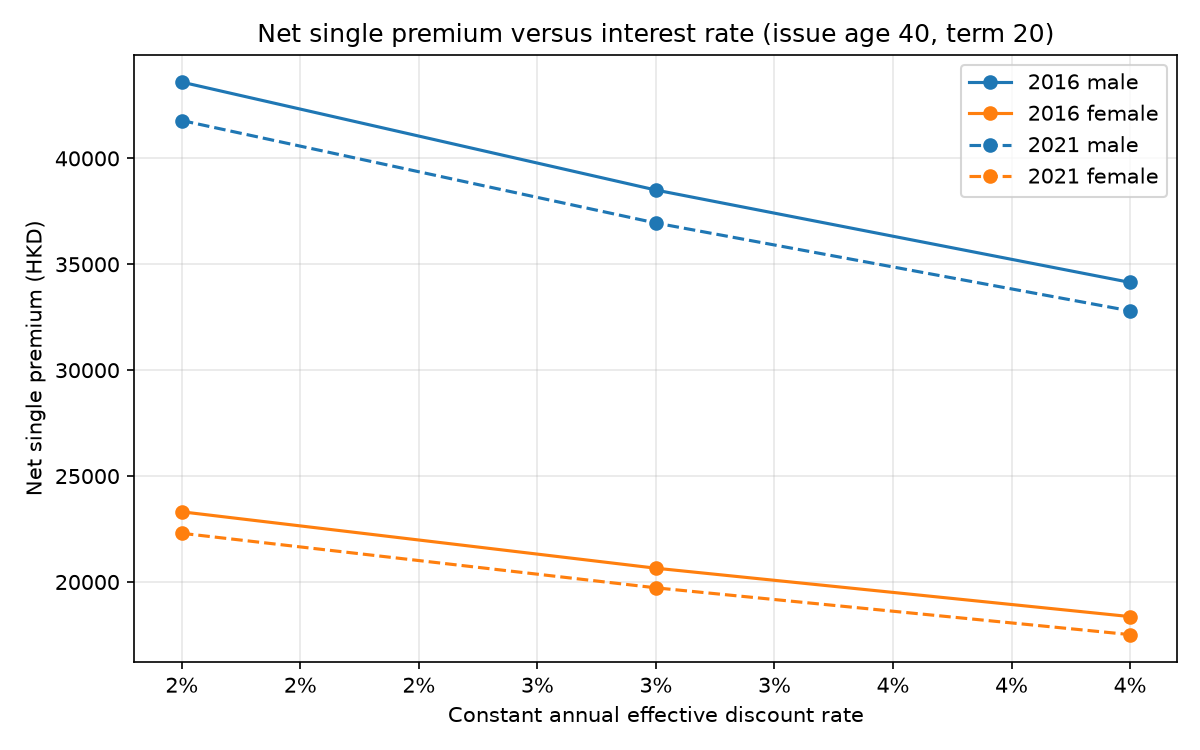

/Users/kingstonpoon/Desktop/Mortality_pricing/results/pv_contribution_male.png


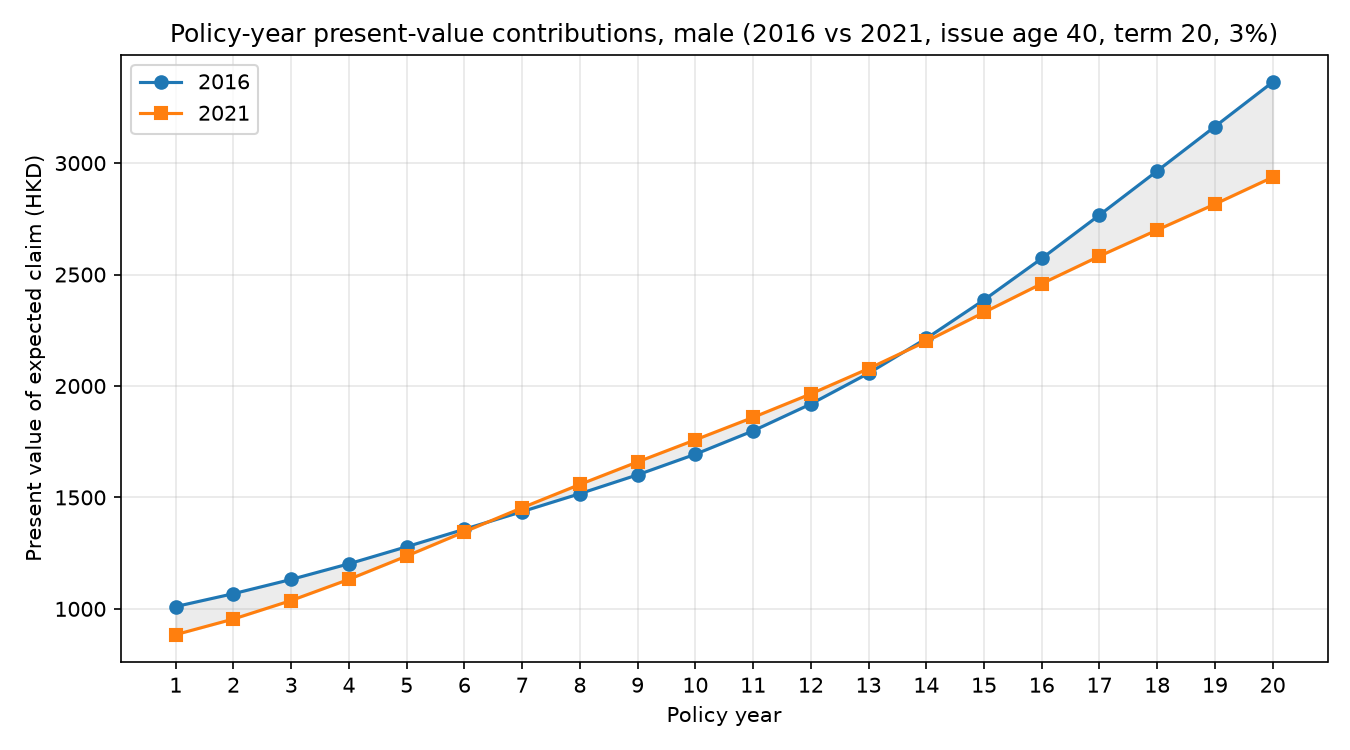

In [8]:
from IPython.display import Image, display

png1, csv1 = plots.mortality_curves(tidy)
png2, csv2 = plots.premium_vs_interest(sens)
contrib = analysis.pv_contribution_diff(tidy, 'male', BASE_INPUTS)
png3, csv3 = plots.pv_contribution(contrib, sex='male')

for png in (png1, png2, png3):
    print(png)
    display(Image(filename=str(png)))

## Distinctive explanation — which years drive the difference?

For males, the signed per-policy-year contribution differences (`pv_claim_2016 − pv_claim_2021`) must sum exactly to the total premium difference. The largest contributions are at the end of the term.

In [9]:
total_diff = contrib['difference'].sum()
prem_diff = analysis.total_premium_difference(tidy, 'male', BASE_INPUTS)

print(f'sum of per-year differences (2016 male - 2021 male) = {total_diff:,.2f}')
print(f'total premium difference (2016 - 2021)              = {prem_diff:,.2f}')
print(f'exact match: {abs(total_diff - prem_diff) < 1e-8}')

(contrib
 .assign(abs_diff=lambda d: d['difference'].abs())
 .sort_values('abs_diff', ascending=False)
 [['policy_year', 'attained_age', 'difference']]
 .head(5))

sum of per-year differences (2016 male - 2021 male) = 1,555.96
total premium difference (2016 - 2021)              = 1,555.96
exact match: True


,policy_year,attained_age,difference
19,20,59,426.664345
18,19,58,348.032200
17,18,57,264.861422
16,17,56,184.583222
0,1,40,125.961165
